# Clasificador supervisado con TF-IDF: AG News

**Autora:** Angie Avendaño

Este notebook implementa un pipeline de clasificación supervisada de texto sobre el dataset AG News, con cuatro categorías: Business, Sci_Tech, Sports y World. El flujo es: carga de datos, preprocesamiento, vectorización TF-IDF, entrenamiento de un clasificador baseline y evaluación con métricas por clase y matriz de confusión.

**Resultado final:** accuracy de 0.895 y F1 macro de 0.895 sobre el conjunto de prueba (2000 noticias).

In [44]:
!pip install -q nltk scikit-learn pandas matplotlib seaborn

## 1. Preprocesamiento

El texto se limpia en tres pasos: se pasa a minúsculas, se eliminan números, puntuación y símbolos, y luego se tokeniza, se quitan las stop-words de NLTK y se lematiza. Palabras de dos letras o menos se descartan porque aportan poco valor predictivo.

Esta función no aprende nada de los datos, por lo que aplicarla a train y a test por separado no genera data leakage.

In [45]:
import pandas as pd

train = pd.read_csv("ag_news_train.csv")
test = pd.read_csv("ag_news_test.csv")

print(train.shape, test.shape)
print(train.columns.tolist())
print(train.head(3))
print(train["label"].value_counts())  # distribución de clases

y_train = train["label"]
y_test = test["label"]

(8000, 2) (2000, 2)
['text', 'label']
                                                text     label
0  Red Hat Appoints New CFO. September 2, 2004 --...  Sci_Tech
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...  Sci_Tech
2  Radio Outage Grounds West Coast Flights. Airpo...  Business
label
Sci_Tech    2000
Business    2000
Sports      2000
World       2000
Name: count, dtype: int64


In [46]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Descargas necesarias (solo la primera vez)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

STOP_WORDS = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def limpiar_texto(texto: str) -> str:
    """Pasa a minúsculas y elimina todo lo que no sea letra."""
    texto = texto.lower()
    texto = re.sub(r"[^a-z\s]", " ", texto)   # quita números, puntuación y símbolos
    texto = re.sub(r"\s+", " ", texto).strip()  # colapsa espacios
    return texto

def tokenizar_y_lematizar(texto: str) -> str:
    """Tokeniza, quita stop-words, lematiza y devuelve el texto de nuevo como string."""
    tokens = texto.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in STOP_WORDS and len(t) > 2]
    return " ".join(tokens)

def preprocesar(texto: str) -> str:
    return tokenizar_y_lematizar(limpiar_texto(texto))

# Aplicar a train y test
train["text_clean"] = train["text"].apply(preprocesar)
test["text_clean"] = test["text"].apply(preprocesar)

# Verificación
print(train[["text", "text_clean"]].head(3))
print(train["label"].value_counts().sort_index())

                                                text  \
0  Red Hat Appoints New CFO. September 2, 2004 --...   
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...   
2  Radio Outage Grounds West Coast Flights. Airpo...   

                                          text_clean  
0  red hat appoints new cfo september web host in...  
1  sprint sbc hotspot roaming deal sprint sbc com...  
2  radio outage ground west coast flight airport ...  
label
Business    2000
Sci_Tech    2000
Sports      2000
World       2000
Name: count, dtype: int64


## 2. Vectorización TF-IDF

El `TfidfVectorizer` se ajusta **solo con el conjunto de entrenamiento** (`fit_transform`) y luego se aplica al de prueba (`transform`). Así el vocabulario y los pesos IDF se calculan únicamente con datos de train, evitando que el modelo vea información del test.

La primera celda es una configuración exploratoria (20000 términos con unigramas y bigramas). Su propósito es verificar que el pipeline funciona; el modelo final usa la configuración que se elige en la sección 3.

In [47]:
# Exploratorio: configuración inicial (20000 vocabulario, unigramas + bigramas)
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=20000,     # limita el vocabulario para evitar sobreajuste y consumo excesivo de RAM
    ngram_range=(1, 2),     # unigramas y bigramas
    sublinear_tf=True,      # escala logarítmica de la frecuencia; suele ayudar en texto
    min_df=2                # ignora términos que aparecen en menos de 2 documentos
)

# Ajustar SOLO con train
X_train = vectorizer.fit_transform(train["text_clean"])

# Solo transformar test, con el vocabulario aprendido de train
X_test = vectorizer.transform(test["text_clean"])

y_train = train["label"]
y_test = test["label"]

print("Forma X_train:", X_train.shape)
print("Forma X_test: ", X_test.shape)
print("Tamaño del vocabulario:", len(vectorizer.vocabulary_))

Forma X_train: (8000, 20000)
Forma X_test:  (2000, 20000)
Tamaño del vocabulario: 20000


Como referencia, Naive Bayes sobre la misma configuración final (10000 unigramas) obtuvo un accuracy de 0.889, por debajo de Regresión Logística (0.895). Se mantiene Regresión Logística como modelo final por su interpretabilidad y porque entrega probabilidades de clase.

## 3. Selección de hiperparámetros

Se probaron combinaciones de `max_features` (5000, 10000 y 20000) y `ngram_range` (unigramas y unigramas + bigramas), midiendo accuracy y F1 macro con Regresión Logística. Cada configuración reajusta su vectorizador solo con train.

| max_features | ngram_range | Accuracy | F1 macro |
|---|---|---|---|
| 10000 | (1, 1) | 0.8955 | 0.8954 |
| 20000 | (1, 1) | 0.8950 | 0.8950 |
| 5000 | (1, 1) | 0.8940 | 0.8940 |
| 20000 | (1, 2) | 0.8935 | 0.8934 |
| 10000 | (1, 2) | 0.8910 | 0.8910 |
| 5000 | (1, 2) | 0.8880 | 0.8880 |

Los unigramas igualan o superan a los bigramas en las tres configuraciones de vocabulario. Las diferencias entre configuraciones son pequeñas (menos de 0.01), por lo que se elige la más simple con mejor rendimiento: **10000 unigramas**, que además usa menos memoria que la de 20000.

In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
import pandas as pd

resultados = []

for max_feat in [5000, 10000, 20000]:
    for ngram in [(1, 1), (1, 2)]:
        # Vectorizador nuevo en cada configuración
        vec = TfidfVectorizer(
            max_features=max_feat,
            ngram_range=ngram,
            sublinear_tf=True,
            min_df=2
        )
        X_tr = vec.fit_transform(train["text_clean"])   # fit solo en train
        X_te = vec.transform(test["text_clean"])        # transform en test

        modelo = LogisticRegression(max_iter=1000, random_state=42)
        modelo.fit(X_tr, y_train)
        y_pred = modelo.predict(X_te)

        resultados.append({
            "max_features": max_feat,
            "ngram_range": str(ngram),
            "accuracy": round((y_pred == y_test).mean(), 4),
            "f1_macro": round(f1_score(y_test, y_pred, average="macro"), 4)
        })

df_resultados = pd.DataFrame(resultados).sort_values("f1_macro", ascending=False)
print(df_resultados.to_string(index=False))

 max_features ngram_range  accuracy  f1_macro
        10000      (1, 1)    0.8955    0.8954
        20000      (1, 1)    0.8950    0.8950
         5000      (1, 1)    0.8940    0.8940
        20000      (1, 2)    0.8935    0.8934
        10000      (1, 2)    0.8910    0.8910
         5000      (1, 2)    0.8880    0.8880


In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Configuración final elegida en el paso 6
vectorizer_final = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 1),
    sublinear_tf=True,
    min_df=2
)

# Fit solo con train; transform con test (sin data leakage)
X_train = vectorizer_final.fit_transform(train["text_clean"])
X_test = vectorizer_final.transform(test["text_clean"])

# Modelo final
modelo_final = LogisticRegression(max_iter=1000, random_state=42)
modelo_final.fit(X_train, y_train)
y_pred_final = modelo_final.predict(X_test)

print(classification_report(y_test, y_pred_final, digits=3))

              precision    recall  f1-score   support

    Business      0.849     0.854     0.851       500
    Sci_Tech      0.869     0.876     0.873       500
      Sports      0.951     0.968     0.959       500
       World      0.913     0.884     0.898       500

    accuracy                          0.895      2000
   macro avg      0.896     0.895     0.895      2000
weighted avg      0.896     0.895     0.895      2000



In [50]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Comparación con Naive Bayes sobre la configuración final (10000 unigramas)
modelo_nb = MultinomialNB().fit(X_train, y_train)
print("Accuracy Naive Bayes:", round(accuracy_score(y_test, modelo_nb.predict(X_test)), 3))

Accuracy Naive Bayes: 0.889


## 4. Modelo final

**Modelo elegido: Regresión Logística.** Se eligió porque es un clasificador lineal que funciona bien sobre matrices TF-IDF dispersas, es eficiente, permite interpretar los pesos de cada término y entrega probabilidades de clase.

**Configuración del vectorizador:** `max_features=10000`, `ngram_range=(1, 1)`, `sublinear_tf=True` (escala logarítmica de la frecuencia, que reduce el peso de términos repetidos) y `min_df=2` (ignora términos que aparecen en un solo documento).

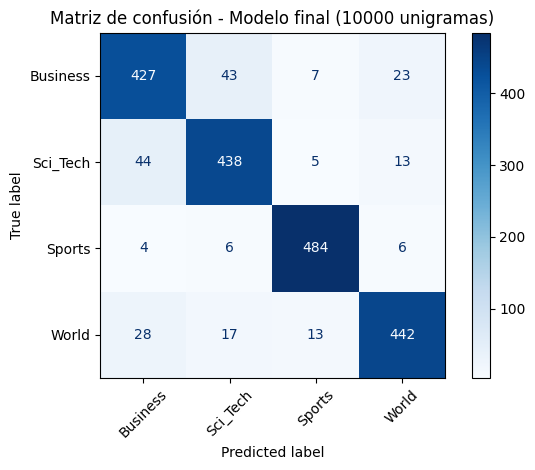

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_final, labels=modelo_final.classes_)
ConfusionMatrixDisplay(cm, display_labels=modelo_final.classes_).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión - Modelo final (10000 unigramas)")
plt.tight_layout()
plt.savefig("matriz_confusion_final.png", dpi=150)
plt.show()

## 5. Análisis preliminar de errores

De las 2000 noticias de prueba, el modelo clasifica incorrectamente 210 (accuracy 0.895). La matriz de confusión muestra que:

- **Business y Sci_Tech son las categorías más difíciles de separar.** Entre ambas suman 87 de los 210 errores (≈41%), con confusiones casi simétricas: 43 noticias de Business se predicen como Sci_Tech y 44 en sentido contrario. Esto es consistente con el solapamiento de vocabulario, ya que muchas noticias tecnológicas tratan sobre resultados financieros o acuerdos empresariales.
- **Sports es la categoría mejor predicha**, con un recall de 0.968 (484 de 500). Su vocabulario es muy específico (equipo, partido, temporada, jugador).
- **World se confunde sobre todo con Business** (28 casos), probablemente por noticias de economía internacional.

## 6. Entorno y reproducibilidad

Versiones de las librerías utilizadas:

- Python 3.13
- pandas 2.2.3
- scikit-learn 1.6.1
- nltk 3.9.1
- matplotlib 3.10.0

La semilla `random_state=42` se fija en el modelo para que los resultados sean reproducibles. Las salidas que aparecen en el notebook corresponden a una ejecución completa con estas versiones.